## SoCG examples

In [2]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
import matplotlib.patches as mpatches

from matplotlib import rc

# rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
rc("font", **{"family": "serif", "serif": ["Times"]})
rc("text", usetex=True)


from math import cos, sin, pi, atan     
import itertools
from scipy.stats import qmc
import math

import numpy.linalg
import random as rnd

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv
import bunny_smaller
import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2



## notes
- output a table: num pts in M and num in N, num omega (unpruned), num omega (pruned) (for each of the three algs)
- pictures of input points (and/or with switch points)


## experiments to comment on: 
- increasing num of rect mods, and seeing how num of omega pts increase
- seeing how unbalanced M vs N changes omega pts
- what is the dependence of num of switch points on num of pts in M and N? 
- unbalanced modules: M has more points than N
- How many duplcate omega points do we get in different cases? 

- multiple instances of 1 rect vs 1 rect
- experiments where num rects increases

## Poisson points with blue noise

4


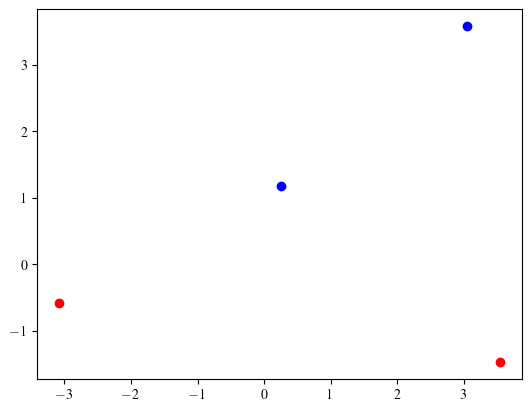

In [96]:
# num of verts to match bunny (or close) : poisson intensity
# 4 1.3
# 9 2.5
# 16 5.5
# 24 ! No, 23 9.19
# 34 12

poisson_intensity = 1.3
seed = 0

critvals = ex.critvals_poisson(poisson_intensity, seed)
print(len(critvals))



**********
Computed 384524 points (with duplicates)
Without duplicates 293853
**********
Computed 61216 points (with duplicates)
Without duplicates 61216
**********
Computed 64857 points (with duplicates)
Without duplicates 64857


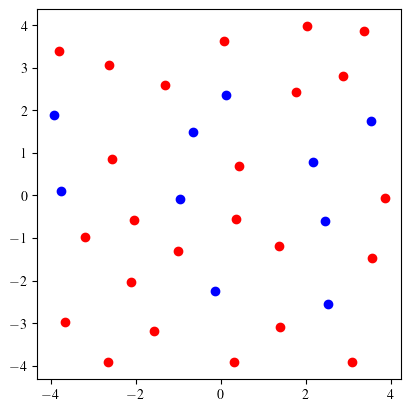

In [101]:
# num of verts to match bunny (or close) : poisson intensity
# 4 1.3
# 9 2.5
# 16 5.5
# 24 ! No, 23 9.19
# 34 12

poisson_intensity = 12
seed = 0

critvals, no_lub = ex.critvals_poisson(poisson_intensity, seed)

###############
title = "Poisson"
# dpi = 300
############# do computations
# algo 3v1 = Algorithm 3 in SoCG overleaf
omegapts_3v1, _, _ = omega.output_alg_3_1(critvals, "socg/" + title)

# algo 2v2 paired = Algorithm 5 in SoCG overleaf
omegapts_2v2_p, _, _, is_inf, orderedomegas = omega.output_alg_2_2_paired(
    critvals, "socg/" + title
)

# algo 2v2 unpaired = Algorithm 7 in SoCG overleaf
omegapts_2v2_unp, _, _, is_inf2, orderedomegas2 = omega.output_alg_2_2_unpaired(
    critvals, "socg/" + title
)

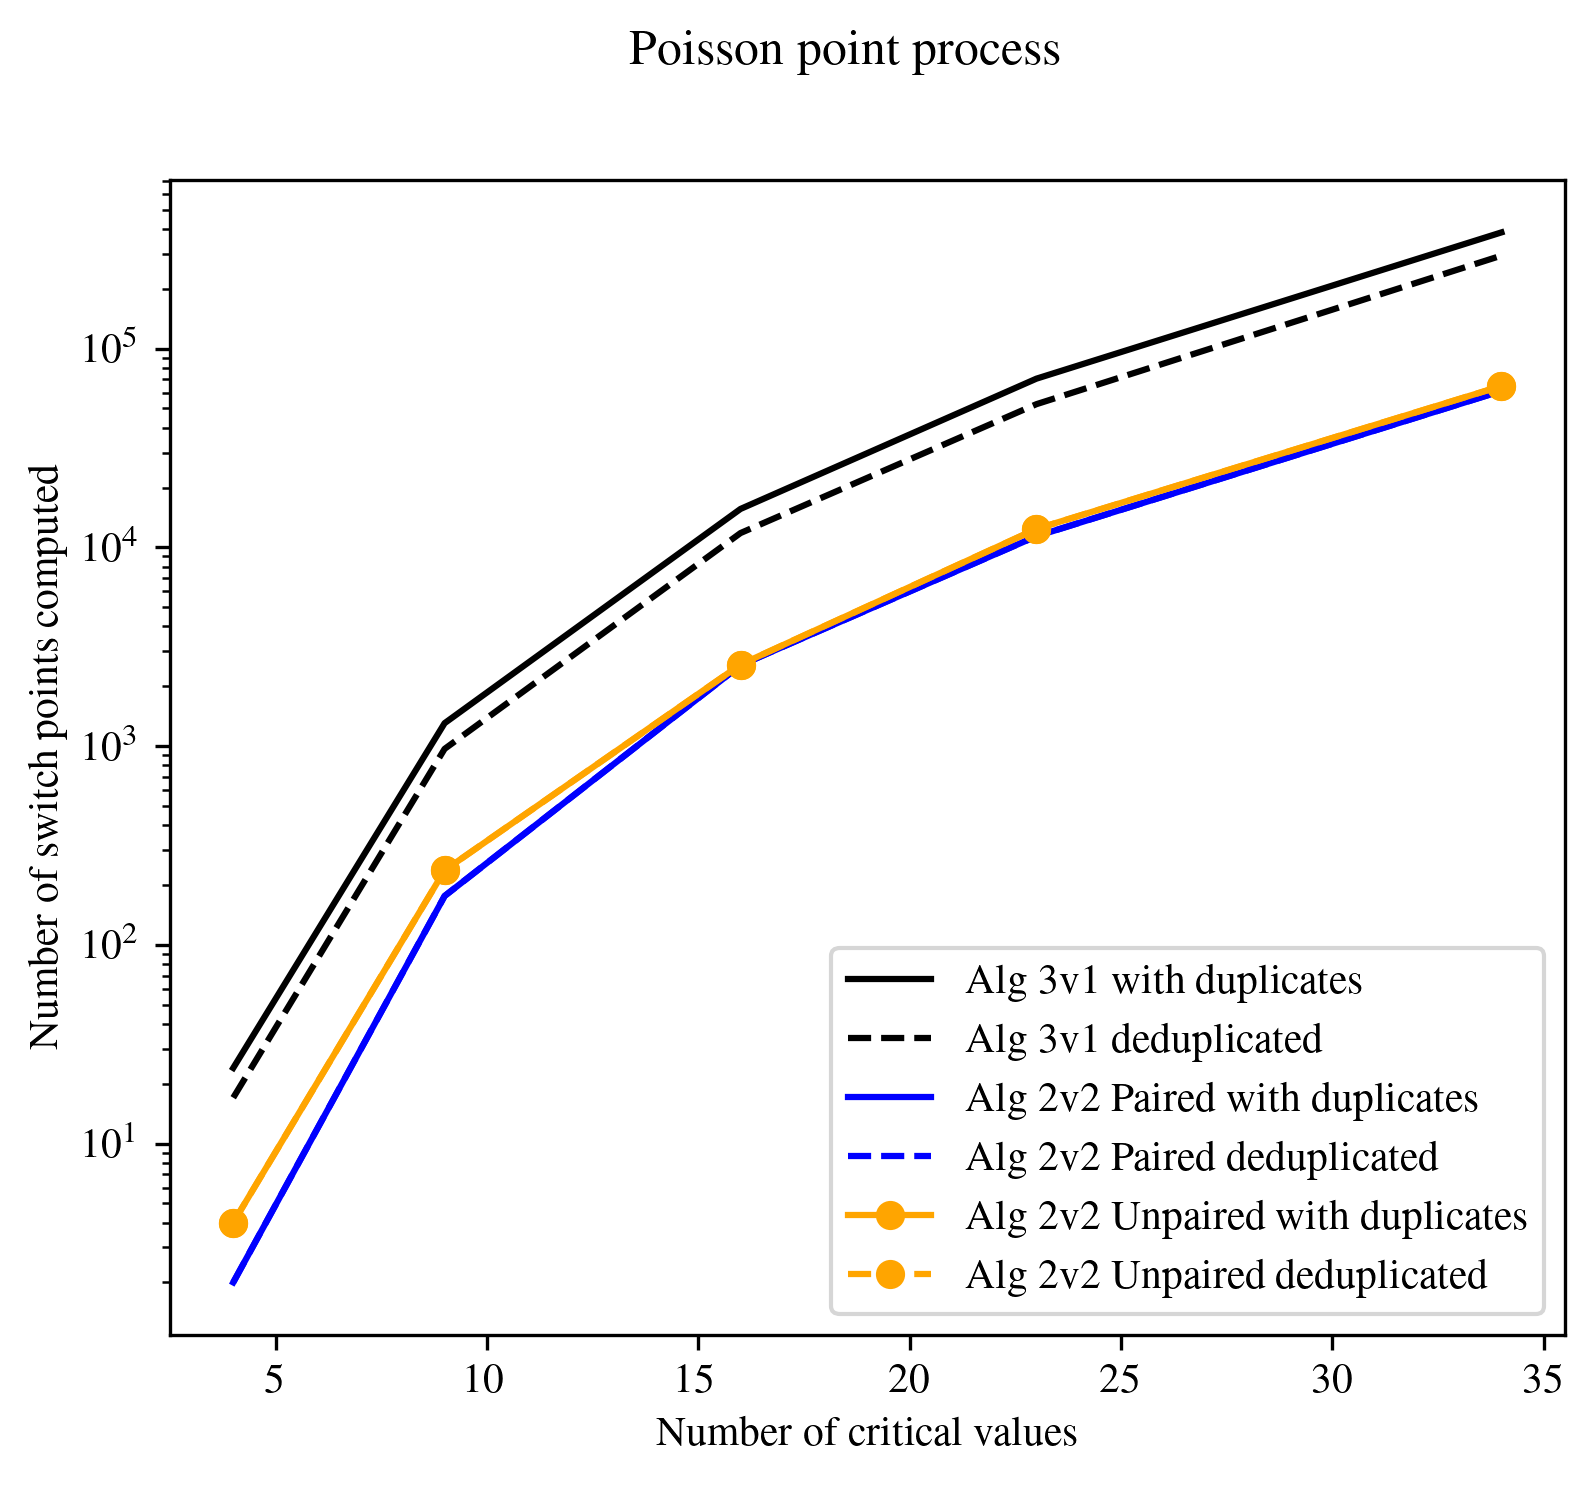

In [106]:
title = "Poisson point process"
dpi = 300

############ make the example
fig, ax = plt.subplots()
fig.set_dpi(dpi)
fig.set_size_inches(6, 5)
# fig.tight_layout
fig.suptitle(title)

## bunnies
# x is number of verts, so num crit vals
x = [4, 9, 16, 23, 34]

# 3v1
y_3v1_duplic = [24, 1304, 15607, 70612, 384524]
y_3v1_no_duplic = [17, 968, 11802, 52541, 293853]
ax.plot(x, y_3v1_duplic, "k-", label="Alg 3v1 with duplicates")
ax.plot(x, y_3v1_no_duplic, "k--", label="Alg 3v1 deduplicated")

# 2v2 p
y_2v2p_duplic = [2, 176, 2551, 11376, 61216]
y_2v2p_no_duplic = [2, 176, 2551, 11376, 61216]
ax.plot(x, y_2v2p_duplic, "b-", label="Alg 2v2 Paired with duplicates")
ax.plot(x, y_2v2p_no_duplic, "b--", label="Alg 2v2 Paired deduplicated")

# 2v2 unp
y_2v2unp_duplic = [4, 237, 2572, 12384, 64857]
y_2v2unp_no_duplic = [4, 237, 2572, 12384, 64857]
ax.plot(x, y_2v2unp_duplic, "o-", color = "orange", label="Alg 2v2 Unpaired with duplicates")
ax.plot(x, y_2v2unp_no_duplic, "o--", color = "orange", label="Alg 2v2 Unpaired deduplicated")

# ax.set_yscale("log")
plt.xlabel("Number of critical values")
plt.ylabel("Number of switch points computed")
ax.legend()
ax.set_yscale("log")

## Flattened bunny

4

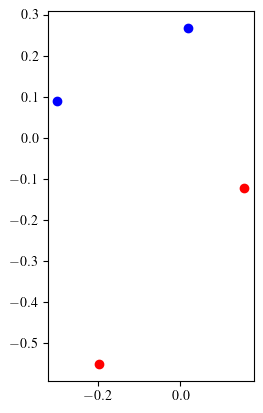

In [52]:
import bunny_003

bunnypoints = bunny_003.bunny_006()
seed = 4
critvals = ex.bunny_into_critvals(bunnypoints, seed)
len(bunnypoints)

**********
Computed 26 points (with duplicates)
Without duplicates 13
**********
Computed 2 points (with duplicates)
Without duplicates 2
**********
Computed 2 points (with duplicates)
Without duplicates 2


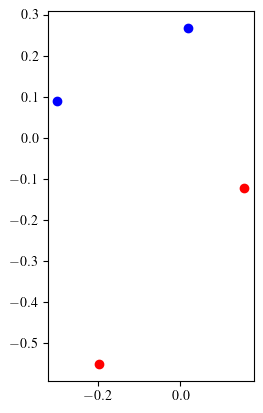

In [53]:
import bunny_003
bunnypoints = bunny_003.bunny_006()
seed = 4
critvals = ex.bunny_into_critvals(bunnypoints, seed)

###############
title = "Bunny"
# dpi = 300
############# do computations
# algo 3v1 = Algorithm 3 in SoCG overleaf
# never has points at infinity, so we can plot all points
omegapts_3v1, _, _ = omega.output_alg_3_1(critvals, "socg/" + title)
#ourplot.plot_both_c_o(bunnypoints, omegapts_3v1, title, dpi, "3v1")

# algo 2v2 paired = Algorithm 5 in SoCG overleaf
omegapts_2v2_p, _, _, is_inf, orderedomegas = omega.output_alg_2_2_paired(
    critvals, "socg/" + title
)
#ourplot.plot_c_o_with_inf(bunnypoints, orderedomegas, is_inf, title, dpi, "2v2 Paired")

# algo 2v2 unpaired = Algorithm 7 in SoCG overleaf
omegapts_2v2_unp, _, _, is_inf2, orderedomegas2 = omega.output_alg_2_2_unpaired(
    critvals, "socg/" + title
)
#ourplot.plot_c_o_with_inf(
#     bunnypoints, orderedomegas2, is_inf2, title, dpi, "2v2 Unpaired"
# )

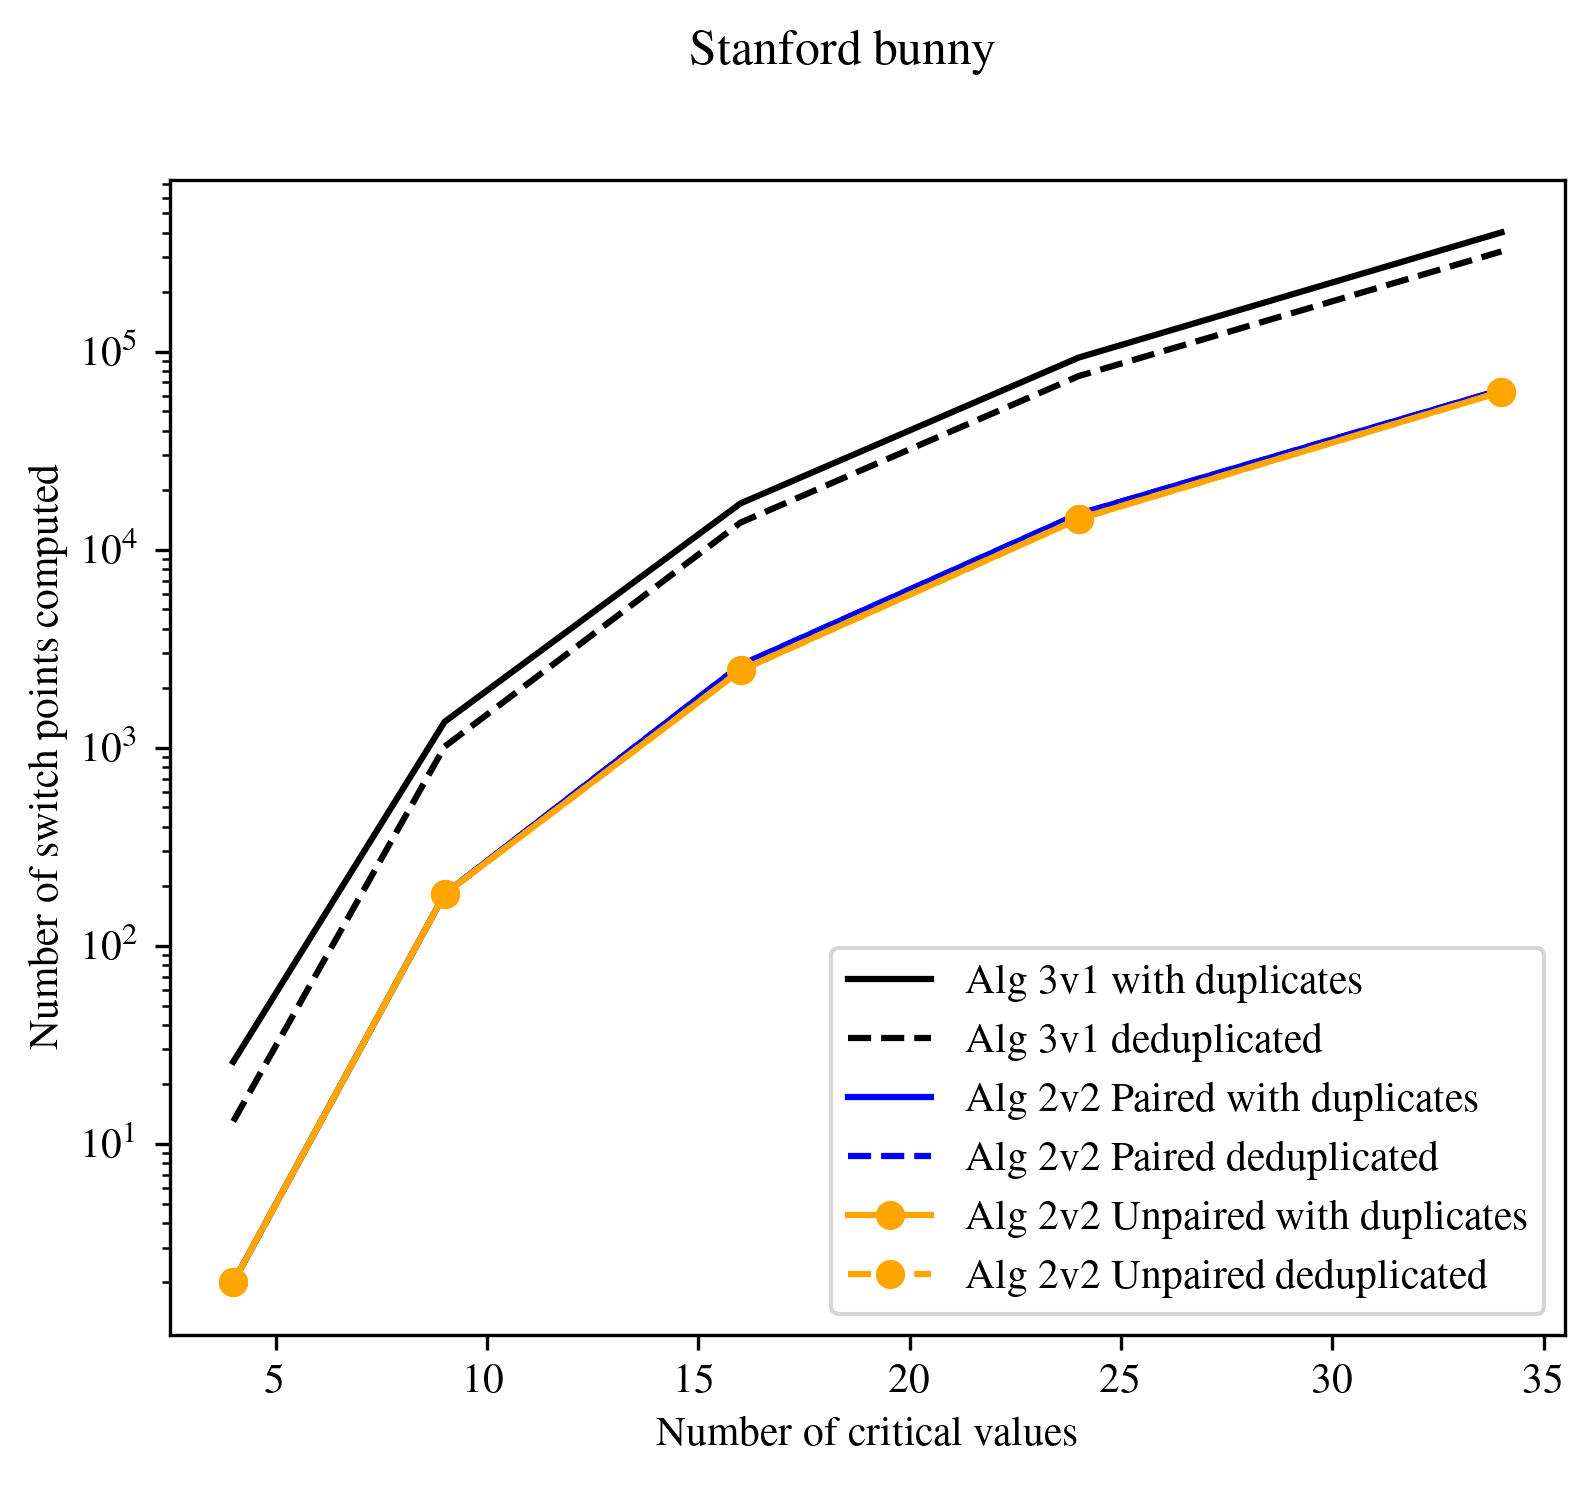

In [107]:
title = "Stanford bunny"
dpi = 300

############ make the example
fig, ax = plt.subplots()
fig.set_dpi(dpi)
fig.set_size_inches(6, 5)
# fig.tight_layout
fig.suptitle(title)

## bunnies
# x is number of verts, so num crit vals
x = [4, 9, 16, 24, 34]

# 3v1
y_3v1_duplic = [26, 1354, 17157, 93494, 400607]
y_3v1_no_duplic = [13, 1015, 13722, 75390, 321203]
ax.plot(x, y_3v1_duplic, "k-", label="Alg 3v1 with duplicates")
ax.plot(x, y_3v1_no_duplic, "k--", label="Alg 3v1 deduplicated")

# 2v2 p
y_2v2p_duplic = [2, 183, 2617, 15160, 64300]
y_2v2p_no_duplic = [2, 183, 2617, 15160, 64300]
ax.plot(x, y_2v2p_duplic, "b-", label="Alg 2v2 Paired with duplicates")
ax.plot(x, y_2v2p_no_duplic, "b--", label="Alg 2v2 Paired deduplicated")

# 2v2 unp
y_2v2unp_duplic = [2, 183, 2462, 14322, 62835]
y_2v2unp_no_duplic = [2, 183, 2462, 14322, 62835]
ax.plot(x, y_2v2unp_duplic, "o-", color = "orange", label="Alg 2v2 Unpaired with duplicates")
ax.plot(x, y_2v2unp_no_duplic, "o--", color = "orange", label="Alg 2v2 Unpaired deduplicated")

# ax.set_yscale("log")
plt.xlabel("Number of critical values")
plt.ylabel("Number of switch points computed")
ax.legend()
ax.set_yscale("log")

## Random rect mods

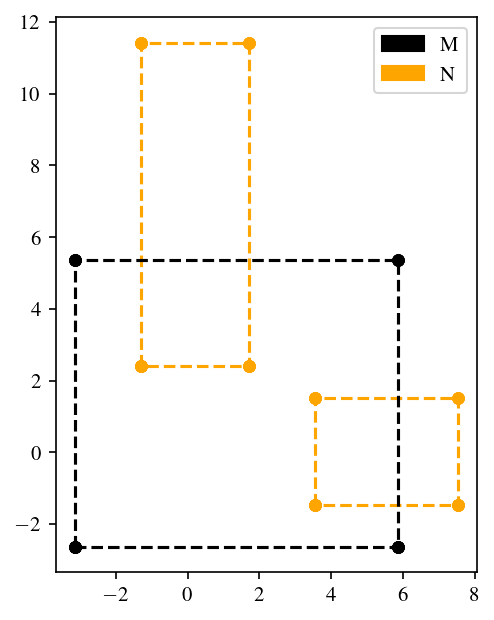

In [9]:
poisson_intensity = .6
# with seed 1: 
# 1 rectangle: .1
# 2: .4
# 3: .6
# 4: 1.2
# 5: 1.4
# 6: 1.6
# 7: 2
# 8: 2.1
# 9: 2.2
# 10: 2.7
seed = 1

critpts, crits_no_lub = ex.make_rects(poisson_intensity, seed = seed, dpi = 150)


num crits:  32
**********
Computed 245874 points (with duplicates)
Without duplicates 26473
**********
Computed 39464 points (with duplicates)
Without duplicates 6224
**********
Computed 42261 points (with duplicates)
Without duplicates 8704


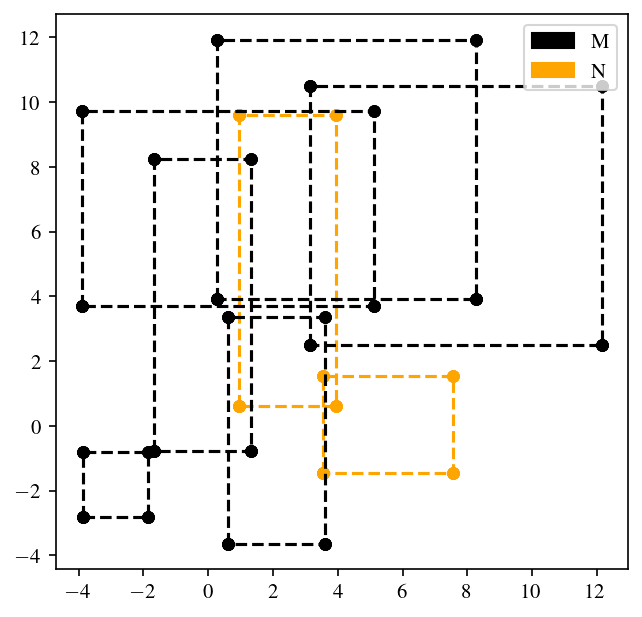

In [114]:
poisson_intensity = 2.1
# with seed 1:
# 1 rectangle: .1
# 2: .4
# 3: .6
# 4: 1.2
# 5: 1.4
# 6: 1.6
# 7: 2
# 8: 2.1
# 9: 2.2
# 10: 2.7
seed = 1

critvals, crits_no_lub = ex.make_rects(poisson_intensity, seed=seed, dpi=150)

print("num crits: ", len(critvals))
###############
title = "Bunny"
# dpi = 300
############# do computations
# algo 3v1 = Algorithm 3 in SoCG overleaf
omegapts_3v1, _, _ = omega.output_alg_3_1(critvals, "socg/" + title)

# algo 2v2 paired = Algorithm 5 in SoCG overleaf
omegapts_2v2_p, _, _, is_inf, orderedomegas = omega.output_alg_2_2_paired(
    critvals, "socg/" + title
)

# algo 2v2 unpaired = Algorithm 7 in SoCG overleaf
omegapts_2v2_unp, _, _, is_inf2, orderedomegas2 = omega.output_alg_2_2_unpaired(
    critvals, "socg/" + title
)

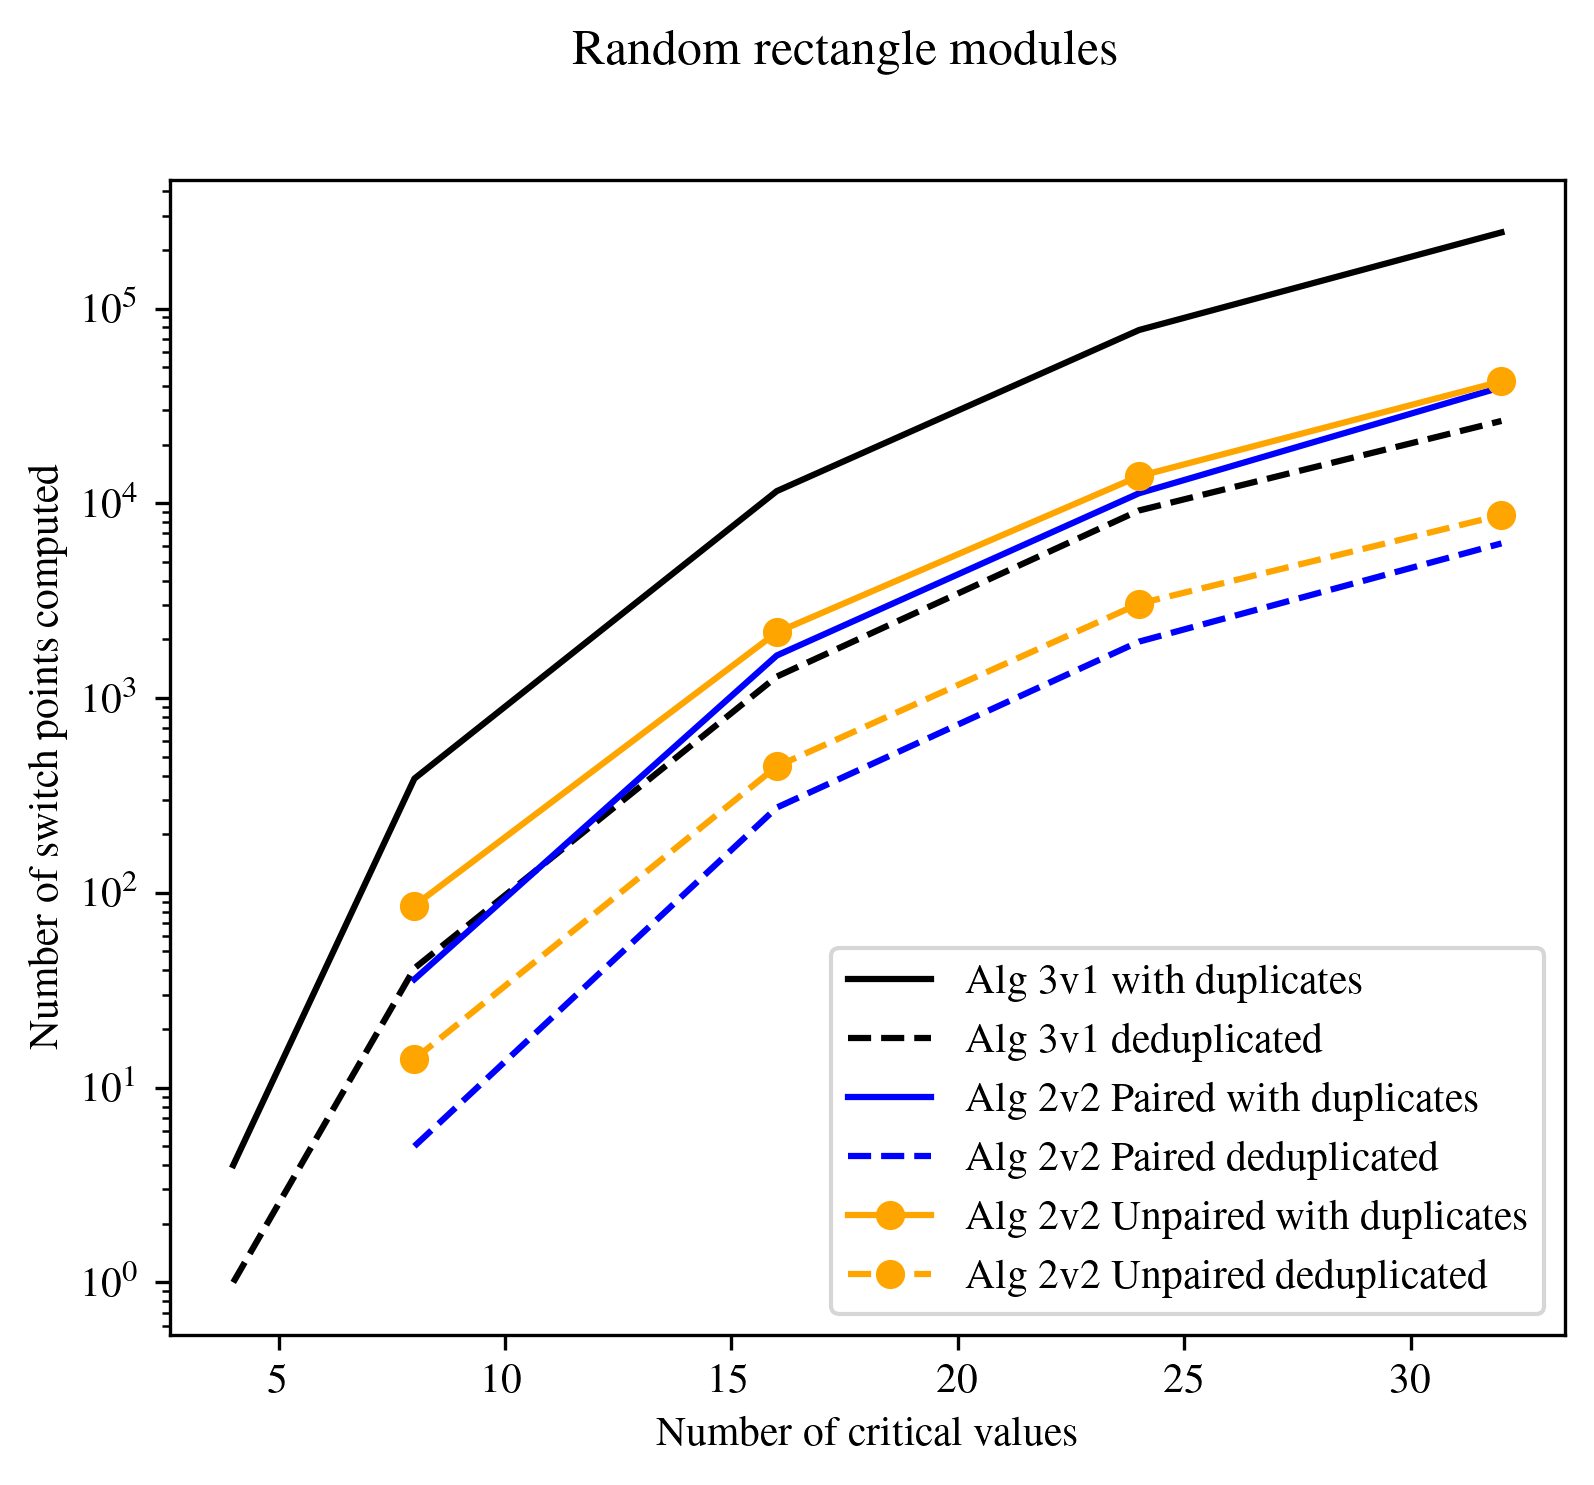

In [117]:
title = "Random rectangle modules"
dpi = 300

############ make the example
fig, ax = plt.subplots()
fig.set_dpi(dpi)
fig.set_size_inches(6, 5)
# fig.tight_layout
fig.suptitle(title)

## bunnies
# x is number of verts, so num crit vals
x = [4, 8, 16, 24, 32]

# 3v1
y_3v1_duplic = [4, 386, 11546, 77561, 245874]
y_3v1_no_duplic = [1, 41, 1289, 9186, 26473]
ax.plot(x, y_3v1_duplic, "k-", label="Alg 3v1 with duplicates")
ax.plot(x, y_3v1_no_duplic, "k--", label="Alg 3v1 deduplicated")

# 2v2 p
x2 = [8, 16, 24, 32]
y_2v2p_duplic = [36, 1654, 11261, 39464]
y_2v2p_no_duplic = [5, 274, 1949, 6224]
ax.plot(x2, y_2v2p_duplic, "b-", label="Alg 2v2 Paired with duplicates")
ax.plot(x2, y_2v2p_no_duplic, "b--", label="Alg 2v2 Paired deduplicated")

# 2v2 unp
y_2v2unp_duplic = [86, 2174, 13777, 42261]
y_2v2unp_no_duplic = [14, 446, 3051, 8704]
ax.plot(
    x2, y_2v2unp_duplic, "o-", color="orange", label="Alg 2v2 Unpaired with duplicates"
)
ax.plot(
    x2, y_2v2unp_no_duplic, "o--", color="orange", label="Alg 2v2 Unpaired deduplicated"
)

# ax.set_yscale("log")
plt.xlabel("Number of critical values")
plt.ylabel("Number of switch points computed")
ax.legend()
ax.set_yscale("log")

## sanity check example

NOTE!!! These figures include infinite omega points. 
\e can discard them, but we have to do that in the omega points file, where we still have the info that they have an omega slope. 

- color the pts differently if from two modules
- draw quarter circle, line with slope m intersects circle at a point, draw that point to repr slope

- is 3v1 never infinite? 

- order is different between csv and output

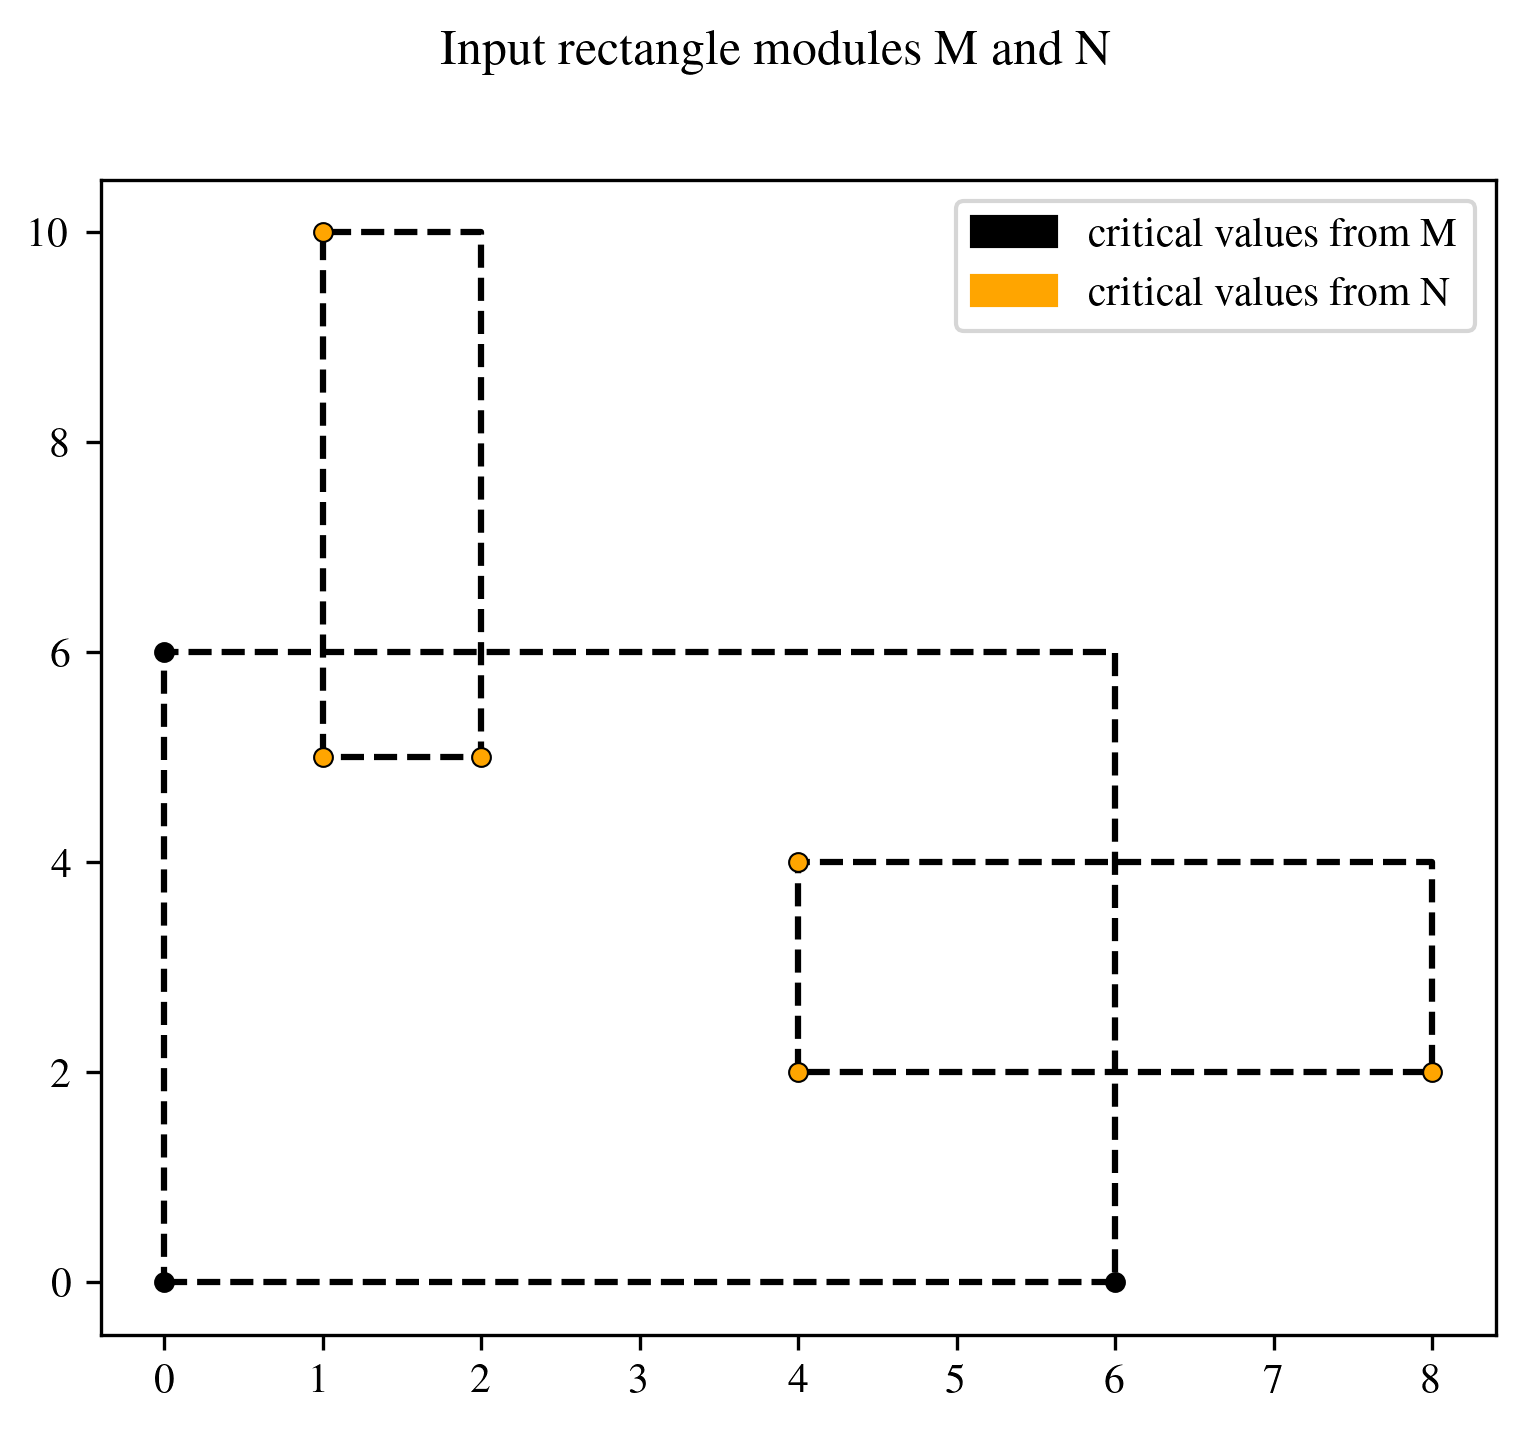

**********
Computed 914 points (with duplicates)
Without duplicates 142
for sanity, num omegas: 142


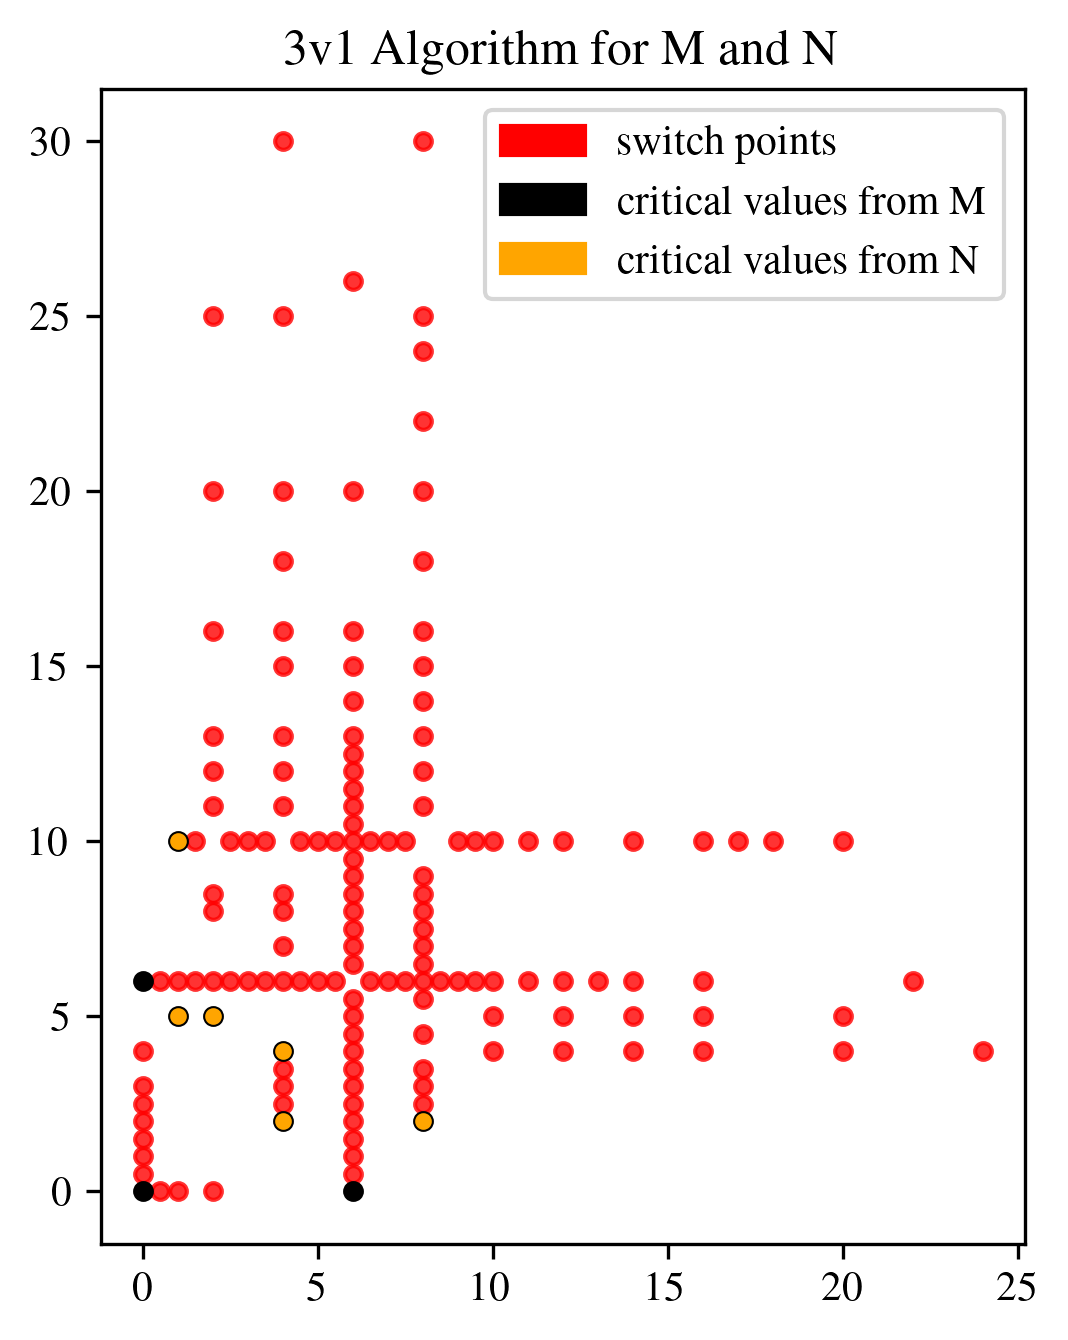

**********
Computed 133 points (with duplicates)
Without duplicates 44
for sanity, num omegas:  44


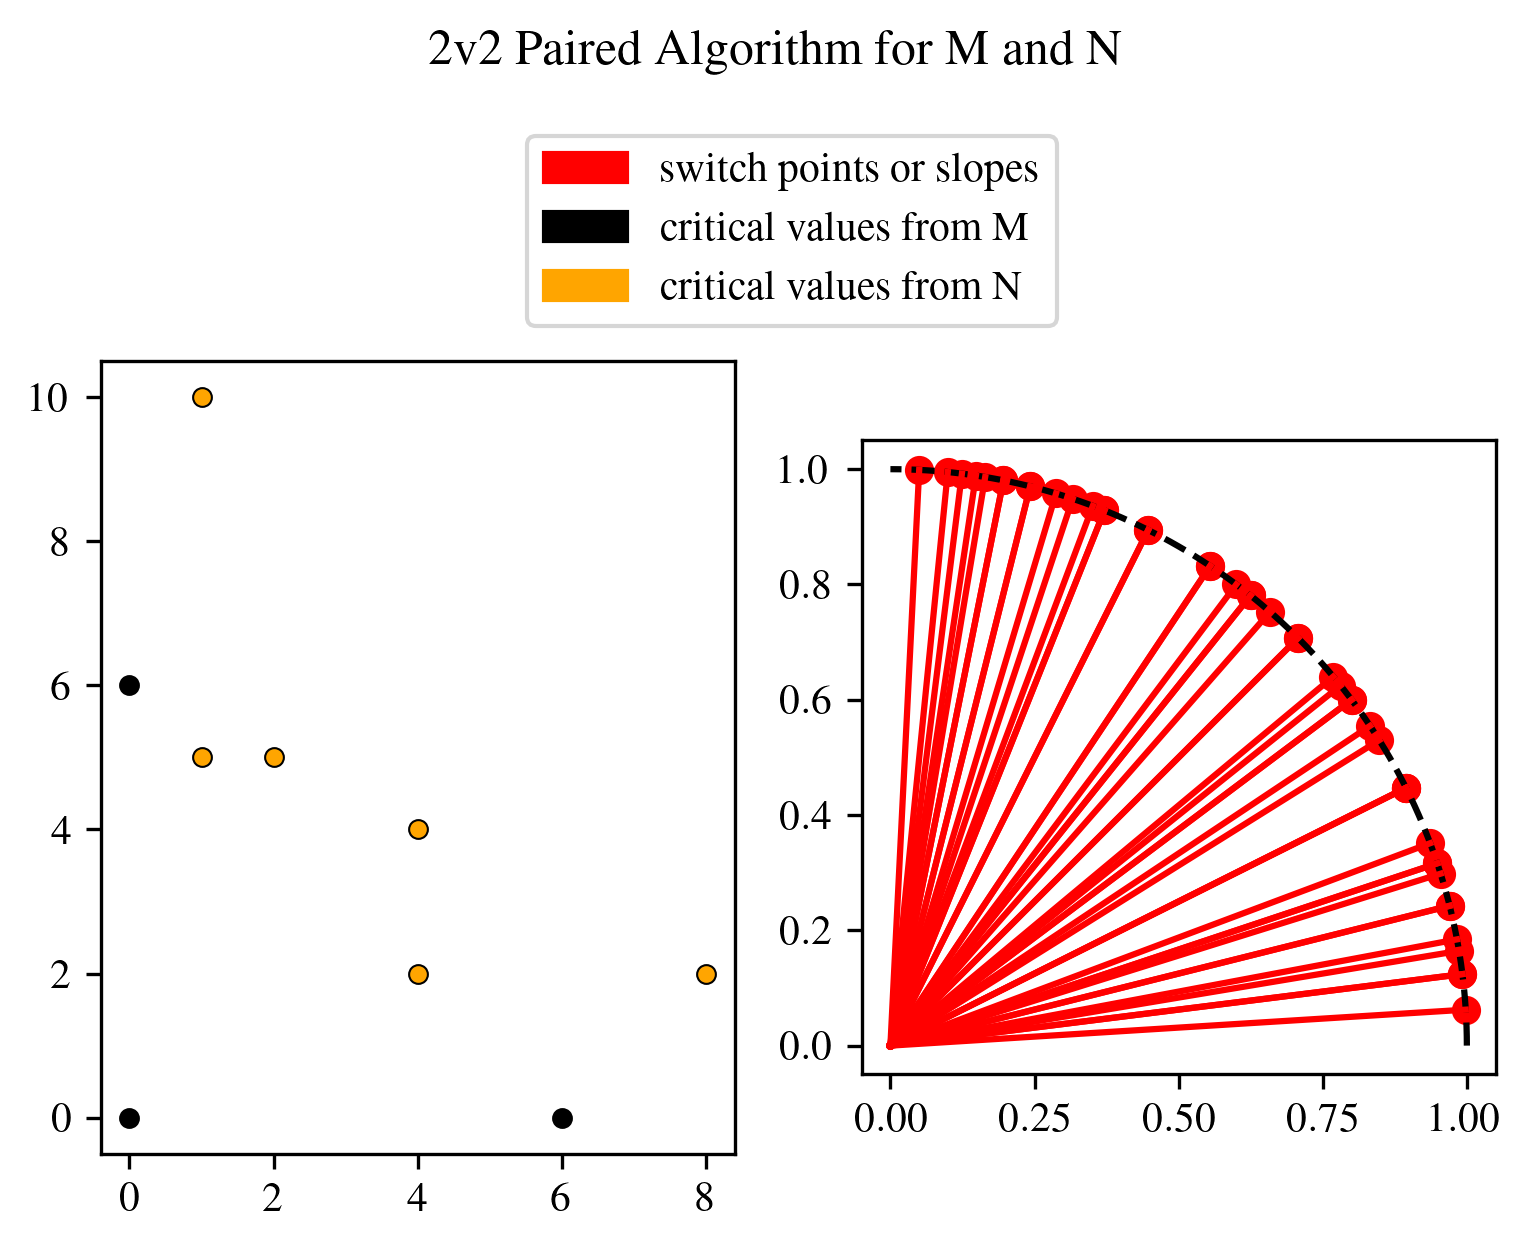

**********
Computed 181 points (with duplicates)
Without duplicates 95
for sanity, num omegas:  95


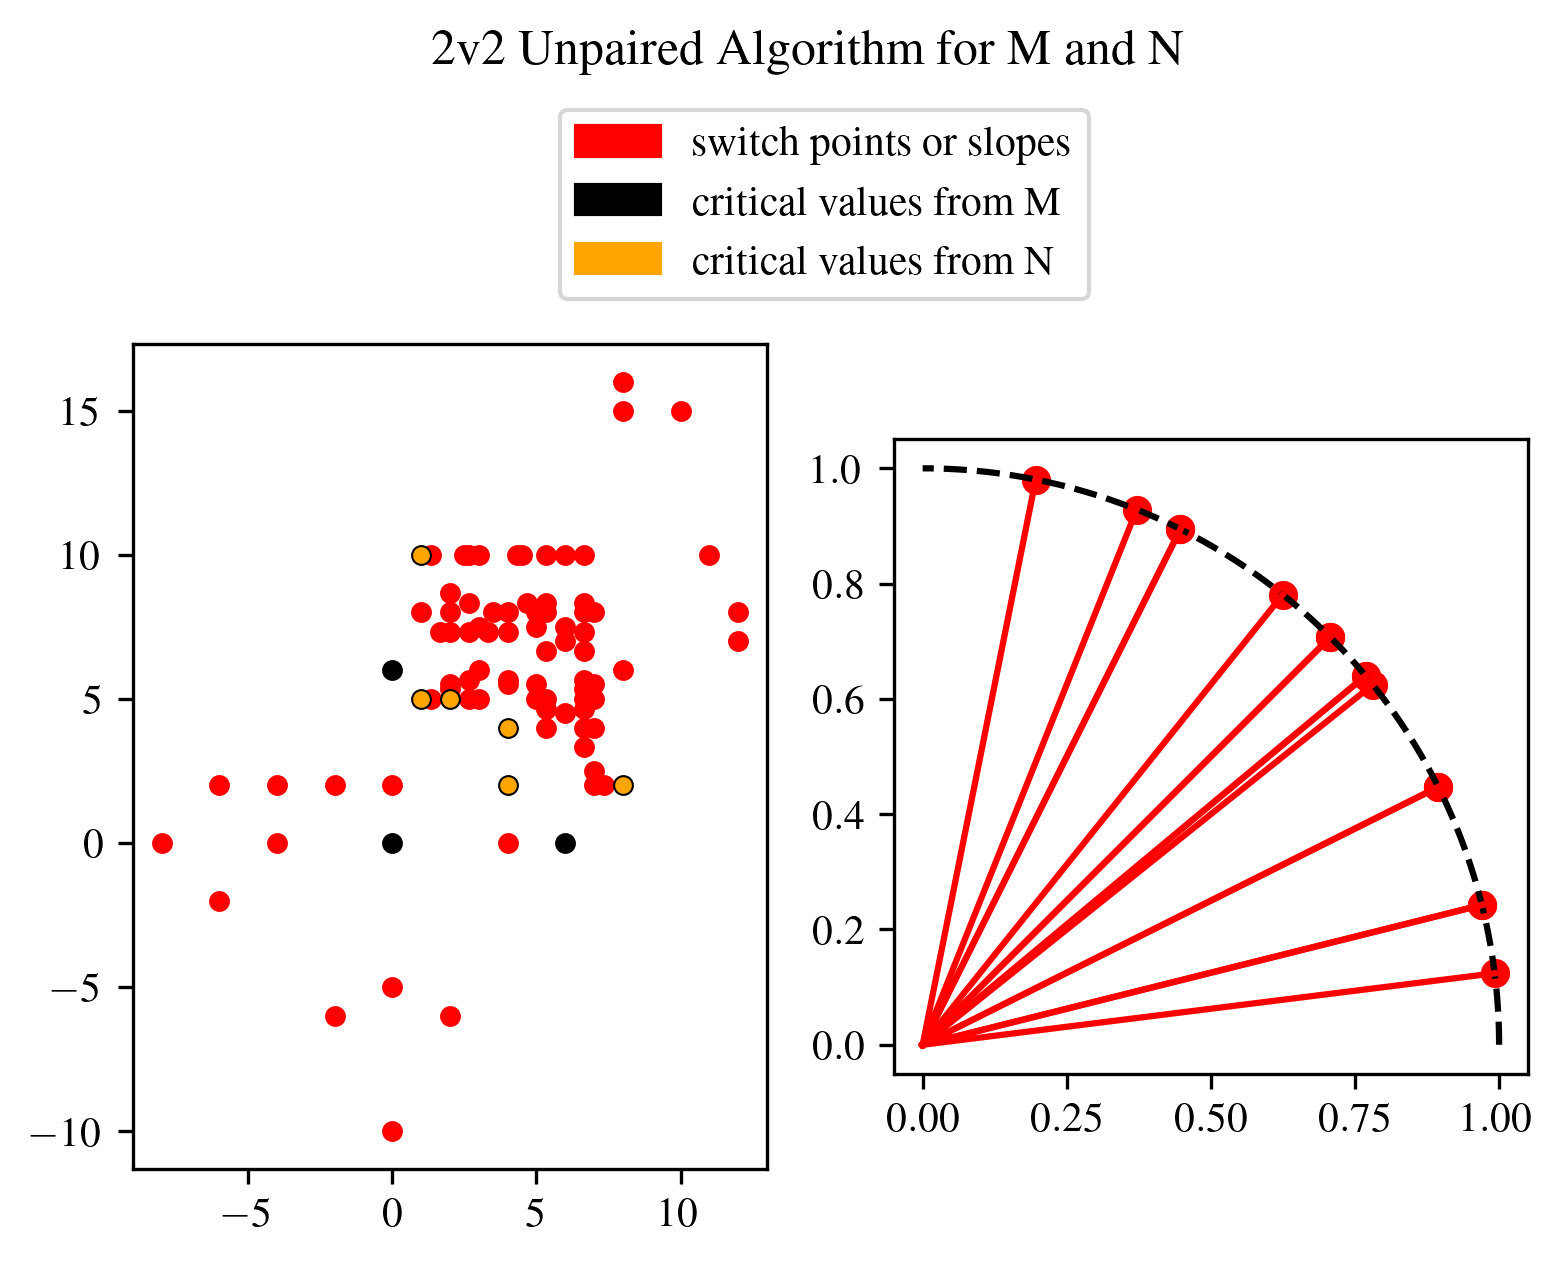

In [43]:
critpts, crits_no_lub = ex.small_socg_ex()
title = "M and N"
dpi = 300

############ make the example
fig, ax0 = plt.subplots()
fig.set_dpi(dpi)
fig.set_size_inches(6, 5)
# fig.tight_layout

fig.suptitle("Input rectangle modules M and N")
for i in [0, 3, 6]:
    p1, p2, p3 = crits_no_lub[0 + i][0], crits_no_lub[1 + i][0], crits_no_lub[2 + i][0]
    p4 = np.array(p2) + np.array(p3) - np.array(p1)
    x = [p1[0], p2[0], p4[0], p3[0], p1[0]]
    y = [p1[1], p2[1], p4[1], p3[1], p1[1]]
    ax0.plot(x, y, "k--")

for c in crits_no_lub:
    if c[1] == 0:
        ax0.plot(
            c[0][0],
            c[0][1],
            "o",
            color="black",
            label="black",
            markersize=4,
        )
    else:
        ax0.plot(
            c[0][0],
            c[0][1],
            "o",
            color="black",
            markersize=4,
        )
        ax0.plot(
            c[0][0],
            c[0][1],
            "o",
            color="orange",
            label="orange",
            markersize=3,
        )


black_patch = mpatches.Patch(color="black", label="critical values from M")
orange_patch = mpatches.Patch(color="orange", label="critical values from N")
ax0.legend(
    handles=[black_patch, orange_patch],
    loc="upper right",
)
plt.show()


############# do computations
# algo 3v1 = Algorithm 3 in SoCG overleaf
# never has points at infinity, so we can plot all points
omegapts_3v1, _, _ = omega.output_alg_3_1(critpts, "socg/" + title)
ourplot.plot_both_c_o(crits_no_lub, omegapts_3v1, title, dpi, "3v1")

# algo 2v2 paired = Algorithm 5 in SoCG overleaf
omegapts_2v2_p, _, _, is_inf, orderedomegas = omega.output_alg_2_2_paired(
    critpts, "socg/" + title
)
ourplot.plot_c_o_with_inf(crits_no_lub, orderedomegas, is_inf, title, dpi, "2v2 Paired")

# algo 2v2 unpaired = Algorithm 7 in SoCG overleaf
omegapts_2v2_unp, _, _, is_inf2, orderedomegas2 = omega.output_alg_2_2_unpaired(
    critpts, "socg/" + title
)
ourplot.plot_c_o_with_inf(
    crits_no_lub, orderedomegas2, is_inf2, title, dpi, "2v2 Unpaired"
)